# Stress tests of the main claim (Addendum B of `docs/analysis-plan.md`)

Claim: *a hypoxia-response program is higher in early-onset PE villous tissue than in preterm
controls and FGR-only placentas.* Addendum B was committed before these tests were run.
Run notebooks 01 and 02 first.

- **B1** Null calibration with expression-matched random gene sets
- **B2** Link to FLT1 (gene for sFlt-1, a clinical PE biomarker; not in the hypoxia set)
- **B3** Heterogeneity within PE vs clinical severity (descriptive)
- **B4** Placental villi vs maternal decidua
- **B5** Exploratory adjustment for estimated cell composition

In [1]:
import os, sys, warnings
from pathlib import Path
if "google.colab" in sys.modules:
    os.chdir("/content/team/notebooks")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import nnls
import statsmodels.formula.api as smf
from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ROOT = Path("..")
DATA_DIR = ROOT / "openbio-datathon-2026" / "track-01" / "data"
FIG_DIR = ROOT / "figures"; RES_DIR = Path("results")
gmt = {l.split("\t")[0]: l.rstrip("\n").split("\t")[2:] for l in open(ROOT / "data_external" / "h.all.v2024.1.Hs.symbols.gmt")}
HYP, GLY = set(gmt["HALLMARK_HYPOXIA"]), set(gmt["HALLMARK_GLYCOLYSIS"])
SETS = {"hypoxia (all)": HYP, "shared genes": HYP & GLY, "hypoxia-only genes": HYP - GLY}
print("FLT1 in hypoxia set:", "FLT1" in HYP)

def vst_of(counts, meta):
    counts = counts.loc[(counts >= 10).sum(axis=1) >= 5]
    dds = DeseqDataSet(counts=counts.T.astype(int), metadata=meta[["pe_status"]], design="~pe_status",
                       inference=DefaultInference(n_cpus=4), quiet=True)
    dds.fit_size_factors(); dds.vst(use_design=False)
    return pd.DataFrame(dds.layers["vst_counts"], index=counts.columns, columns=counts.index)

counts = pd.read_csv(DATA_DIR / "track01_counts_vt.csv", index_col=0)
meta = pd.read_csv(DATA_DIR / "track01_metadata_vt.csv", index_col=0).loc[counts.columns]
vst = vst_of(counts, meta)
z = (vst - vst.mean()) / vst.std()
def score(zmat, genes):
    return zmat[[g for g in genes if g in zmat.columns]].mean(axis=1)

FLT1 in hypoxia set: False


## B1. Null calibration: is hypoxia special, or would any gene set of this size look different?

In [2]:
pre = meta.index[meta.group != "TB"]
d0 = meta.loc[pre, ["group", "ga_delivery_weeks", "fetal_sex"]].copy()
d0["grp"] = d0.group.map({"iPTB": "iPTB", "EOPE": "EOPE", "EOPE+FGR": "EOPEFGR", "FGR": "FGR"})
zp = z.loc[pre].values
genes = np.array(z.columns)

# The OLS design is fixed, so compute the contrast estimates for many scores at once with linear algebra.
import patsy
X = patsy.dmatrix("C(grp, Treatment('iPTB')) + ga_delivery_weeks + C(fetal_sex)", d0, return_type="dataframe")
B = np.linalg.pinv(X.values)                                  # (p x n): coefficients = B @ y
cols = list(X.columns)
c_eope = np.zeros(len(cols)); c_eope[cols.index("C(grp, Treatment('iPTB'))[T.EOPE]")] = 1
c_pe_fgr = np.zeros(len(cols))
c_pe_fgr[cols.index("C(grp, Treatment('iPTB'))[T.EOPE]")] = 0.5
c_pe_fgr[cols.index("C(grp, Treatment('iPTB'))[T.EOPEFGR]")] = 0.5
c_pe_fgr[cols.index("C(grp, Treatment('iPTB'))[T.FGR]")] = -1
def contrasts(score_matrix):                                  # score_matrix: n_samples x n_scores
    coef = B @ score_matrix
    return c_eope @ coef, c_pe_fgr @ coef

mean_expr = vst.mean()
bins = pd.qcut(mean_expr, 10, labels=False)
rng = np.random.default_rng(42)
N_RAND = 1000
b1 = []
null_store = {}
for name, gs in SETS.items():
    members = sorted(g for g in gs if g in z.columns)  # sorted: set order varies between Python runs
    obs_e, obs_f = contrasts(z.loc[pre, members].mean(axis=1).values[:, None])
    pool = {b: np.array(bins.index[(bins == b) & ~bins.index.isin(members)]) for b in range(10)}
    need = bins.loc[members].value_counts().sort_index()
    rand_scores = np.empty((len(pre), N_RAND))
    for i in range(N_RAND):
        pick = np.concatenate([rng.choice(pool[b], n, replace=False) for b, n in need.items()])
        rand_scores[:, i] = z.loc[pre, pick].mean(axis=1).values
    null_e, null_f = contrasts(rand_scores)
    null_store[name] = (null_e, null_f, obs_e[0], obs_f[0])
    b1.append({"score": name, "n_genes": len(members),
               "EOPE_vs_iPTB_obs": obs_e[0], "null_95th": np.quantile(null_e, 0.95),
               "p_emp_EOPE": (1 + (null_e >= obs_e[0]).sum()) / (N_RAND + 1),
               "PE_vs_FGR_obs": obs_f[0], "null_95th_PEvsFGR": np.quantile(null_f, 0.95),
               "p_emp_PE_vs_FGR": (1 + (null_f >= obs_f[0]).sum()) / (N_RAND + 1)})
b1 = pd.DataFrame(b1).set_index("score"); b1.to_csv(RES_DIR / "B1_null_calibration.csv")
print(b1.round(3).T)

score              hypoxia (all)  shared genes  hypoxia-only genes
n_genes                  177.000        59.000             118.000
EOPE_vs_iPTB_obs           0.537         0.762               0.424
null_95th                  0.139         0.202               0.177
p_emp_EOPE                 0.001         0.001               0.001
PE_vs_FGR_obs              0.354         0.469               0.297
null_95th_PEvsFGR          0.159         0.200               0.188
p_emp_PE_vs_FGR            0.001         0.001               0.001


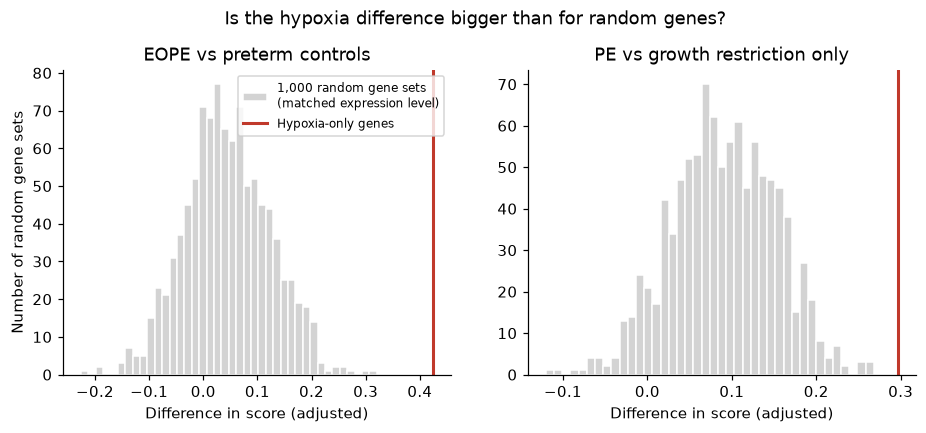

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ne, nf, oe, of = null_store["hypoxia-only genes"]
for ax, null, obs, t in [(axes[0], ne, oe, "EOPE vs preterm controls"), (axes[1], nf, of, "PE vs growth restriction only")]:
    ax.hist(null, bins=40, color="lightgrey", edgecolor="white", label="1,000 random gene sets\n(matched expression level)")
    ax.axvline(obs, c="#c0392b", lw=2, label="Hypoxia-only genes")
    ax.set_xlabel("Difference in score (adjusted)"); ax.set_title(t)
axes[0].set_ylabel("Number of random gene sets"); axes[0].legend(fontsize=8)
fig.suptitle("Is the hypoxia difference bigger than for random genes?", y=1.03)
plt.savefig(FIG_DIR / "fig7_null_calibration.png", dpi=300, bbox_inches="tight"); plt.show()

## B2. Does the hypoxia score track FLT1 (sFlt-1), a clinical PE biomarker gene?

                               set     rho       p
0                 within PE (n=15)  0.7786  0.0006
1                 PE + iPTB (n=20)  0.8391  0.0000
2  pseudobulk STB, 13 early donors  0.7198  0.0055


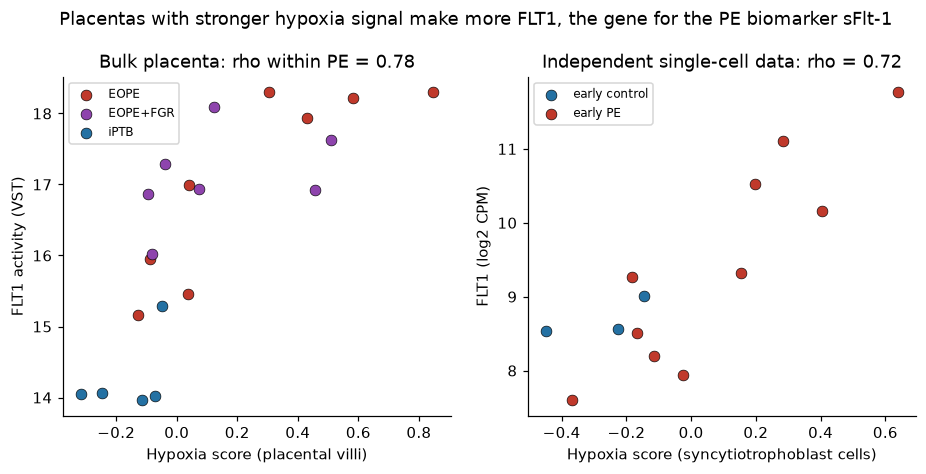

In [4]:
hyp_score = score(z, HYP)
PE = meta.index[meta.pe_status == "PE"]; IPTB = meta.index[meta.group == "iPTB"]
flt1 = vst["FLT1"]
b2 = []
for lab, idx in [("within PE (n=15)", PE), ("PE + iPTB (n=20)", PE.append(IPTB))]:
    r, p = stats.spearmanr(hyp_score[idx], flt1[idx]); b2.append({"set": lab, "rho": r, "p": p})

pb = pd.read_csv(DATA_DIR / "extension" / "pseudobulk" / "track01_pseudobulk_counts.csv", index_col=0)
pbm = pd.read_csv(DATA_DIR / "extension" / "pseudobulk" / "track01_pseudobulk_metadata.csv", index_col=0)
md = pbm[(pbm.cell_class == "syncytiotrophoblast") & pbm.early_onset_comparison.str.startswith("exploratory")]
c = pb[md.index]; c = c.loc[(c >= 10).sum(axis=1) >= 3]
lc = np.log2(c / c.sum() * 1e6 + 1)
zz = lc.sub(lc.mean(1), axis=0).div(lc.std(1).replace(0, np.nan), axis=0)
stb_hyp = zz.loc[zz.index.intersection(list(HYP))].mean()
r, p = stats.spearmanr(stb_hyp, lc.loc["FLT1"]); b2.append({"set": "pseudobulk STB, 13 early donors", "rho": r, "p": p})
b2 = pd.DataFrame(b2); b2.to_csv(RES_DIR / "B2_flt1.csv", index=False); print(b2.round(4))

COL = {"EOPE": "#c0392b", "EOPE+FGR": "#8e44ad", "FGR": "#d68910", "iPTB": "#2471a3", "TB": "#17a589"}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for g in ["EOPE", "EOPE+FGR", "iPTB"]:
    m = meta.group == g
    axes[0].scatter(hyp_score[m], flt1[m], c=COL[g], label=g, s=50, edgecolor="k", lw=0.4)
axes[0].set_xlabel("Hypoxia score (placental villi)"); axes[0].set_ylabel("FLT1 activity (VST)")
axes[0].set_title(f"Bulk placenta: rho within PE = {b2.rho[0]:.2f}"); axes[0].legend(fontsize=8)
isPE = md.pe_status.values == "PE"
axes[1].scatter(stb_hyp[~isPE], lc.loc["FLT1"][~isPE], c="#2471a3", s=50, edgecolor="k", lw=0.4, label="early control")
axes[1].scatter(stb_hyp[isPE], lc.loc["FLT1"][isPE], c="#c0392b", s=50, edgecolor="k", lw=0.4, label="early PE")
axes[1].set_xlabel("Hypoxia score (syncytiotrophoblast cells)"); axes[1].set_ylabel("FLT1 (log2 CPM)")
axes[1].set_title(f"Independent single-cell data: rho = {b2.rho[2]:.2f}"); axes[1].legend(fontsize=8)
fig.suptitle("Placentas with stronger hypoxia signal make more FLT1, the gene for the PE biomarker sFlt-1", y=1.03)
plt.savefig(FIG_DIR / "fig8_flt1_link.png", dpi=300, bbox_inches="tight"); plt.show()

## B3. Heterogeneity within PE: does the hypoxia score follow clinical severity? (descriptive)

In [5]:
dp = meta.loc[PE].copy(); dp["hyp"] = hyp_score[PE]
b3 = []
for col in ["sbp_max_mmhg", "dbp_max_mmhg", "birthweight_lower_g", "ga_delivery_weeks"]:
    r, p = stats.spearmanr(dp.hyp, dp[col], nan_policy="omit"); b3.append({"variable": col, "stat": "Spearman rho", "value": r, "p": p})
u = stats.mannwhitneyu(dp.hyp[dp.fgr_status == "FGR"], dp.hyp[dp.fgr_status == "no_FGR"])
b3.append({"variable": "FGR vs no FGR", "stat": "median diff",
           "value": dp.hyp[dp.fgr_status == "FGR"].median() - dp.hyp[dp.fgr_status == "no_FGR"].median(), "p": u.pvalue})
b3 = pd.DataFrame(b3); b3.to_csv(RES_DIR / "B3_within_PE.csv", index=False); print(b3.round(3))
print("\nPE placentas, sorted by hypoxia score:")
print(dp.sort_values("hyp", ascending=False)[["group", "hyp", "ga_delivery_weeks", "sbp_max_mmhg", "dbp_max_mmhg", "birthweight_interval_g", "qc_flags"]].round(2))

              variable          stat  value      p
0         sbp_max_mmhg  Spearman rho  0.392  0.148
1         dbp_max_mmhg  Spearman rho  0.470  0.077
2  birthweight_lower_g  Spearman rho  0.283  0.306
3    ga_delivery_weeks  Spearman rho  0.293  0.289
4        FGR vs no FGR   median diff -0.099  0.779

PE placentas, sorted by hypoxia score:
              group   hyp  ga_delivery_weeks  sbp_max_mmhg  dbp_max_mmhg  \
sample_id                                                                  
S21_VT         EOPE  0.85              31.86         208.0         117.0   
S22_VT         EOPE  0.58              30.86         189.0         122.0   
S02_VT     EOPE+FGR  0.51              33.43         162.0         118.0   
S25_VT     EOPE+FGR  0.46              33.00         142.0          97.0   
S07_VT         EOPE  0.43              33.00         171.0         100.0   
S18_VT         EOPE  0.31              28.14         176.0         113.0   
S03_VT     EOPE+FGR  0.12              26.57  

## B4. Placental villi vs maternal decidua (same pregnancies)

In [6]:
cdb = pd.read_csv(DATA_DIR / "extension" / "decidua" / "track01_counts_db.csv", index_col=0)
mdb = pd.read_csv(DATA_DIR / "extension" / "decidua" / "track01_metadata_db.csv", index_col=0).loc[cdb.columns]
vst_db = vst_of(cdb, mdb)
z_db = (vst_db - vst_db.mean()) / vst_db.std()
rows, long = [], []
for tissue, zm, mm in [("villi", z, meta), ("decidua", z_db, mdb)]:
    idx = mm.index[mm.group.isin(["EOPE", "EOPE+FGR", "iPTB"])]
    d = mm.loc[idx, ["donor_id", "ga_delivery_weeks", "fetal_sex"]].copy()
    d["PE"] = (mm.loc[idx, "pe_status"] == "PE").astype(int)
    d["hyp"] = score(zm, HYP)[idx]; d["tissue"] = tissue
    f = smf.ols("hyp ~ PE + ga_delivery_weeks + C(fetal_sex)", data=d).fit()
    ci = f.conf_int().loc["PE"]
    rows.append({"tissue": tissue, "n_PE": int(d.PE.sum()), "n_iPTB": int((1 - d.PE).sum()),
                 "PE_coef": f.params["PE"], "CI_low": ci[0], "CI_high": ci[1], "p": f.pvalues["PE"]})
    long.append(d)
long = pd.concat(long)
mix = smf.mixedlm("hyp ~ PE * C(tissue, Treatment('villi')) + ga_delivery_weeks + C(fetal_sex)", long, groups=long.donor_id).fit()
term = [t for t in mix.params.index if t.startswith("PE:")][0]
rows.append({"tissue": "interaction (decidua - villi)", "PE_coef": mix.params[term],
             "CI_low": mix.conf_int().loc[term, 0], "CI_high": mix.conf_int().loc[term, 1], "p": mix.pvalues[term]})
b4 = pd.DataFrame(rows); b4.to_csv(RES_DIR / "B4_villi_vs_decidua.csv", index=False); print(b4.round(3))

                          tissue  n_PE  n_iPTB  PE_coef  CI_low  CI_high  \
0                          villi  15.0     5.0    0.450   0.154    0.747   
1                        decidua  12.0     5.0    0.484   0.139    0.829   
2  interaction (decidua - villi)   NaN     NaN    0.122  -0.195    0.439   

       p  
0  0.005  
1  0.010  
2  0.451  


## B5. Exploratory: does the PE effect survive adjustment for estimated cell composition?

In [7]:
classes = sorted(pbm.cell_class.unique())
cpm_pb = pb / pb.sum() * 1e6
prof = pd.DataFrame({k: cpm_pb[pbm.index[pbm.cell_class == k]].mean(axis=1) for k in classes})
lprof = np.log2(prof + 1)
common = lprof.index.intersection(counts.index)
lprof = lprof.loc[common]
sig = set()
for k in classes:
    spec = lprof[k] - lprof.drop(columns=k).max(axis=1)
    sig |= set(spec[(lprof[k] > 3)].sort_values(ascending=False).index[:50])
sig = sorted(sig)
bulk_cpm = (counts / counts.sum() * 1e6).loc[sig]
P = prof.loc[sig]
props = pd.DataFrame({s: nnls(P.values, bulk_cpm[s].values)[0] for s in bulk_cpm.columns}, index=classes).T
props = props.div(props.sum(axis=1), axis=0)
props.to_csv(RES_DIR / "B5_estimated_proportions.csv")
print(f"{len(sig)} signature genes. Median estimated proportions by group:")
print(props.join(meta.group).groupby("group").median().T.round(3))

d5 = d0.copy(); d5["hyp"] = hyp_score[pre]
d5["stb"] = props.loc[pre, "syncytiotrophoblast"]; d5["ctb"] = props.loc[pre, "villous_cytotrophoblast"]
rows = []
for lab, form in [("A2 model", "hyp ~ C(grp, Treatment('iPTB')) + ga_delivery_weeks + C(fetal_sex)"),
                  ("+ STB and CTB proportions", "hyp ~ C(grp, Treatment('iPTB')) + ga_delivery_weeks + C(fetal_sex) + stb + ctb")]:
    f = smf.ols(form, data=d5).fit()
    t = "C(grp, Treatment('iPTB'))[T.EOPE]"
    rows.append({"model": lab, "EOPE_vs_iPTB": f.params[t], "CI_low": f.conf_int().loc[t, 0], "CI_high": f.conf_int().loc[t, 1], "p": f.pvalues[t]})
b5 = pd.DataFrame(rows); b5.to_csv(RES_DIR / "B5_composition_adjusted.csv", index=False); print(b5.round(3))

700 signature genes. Median estimated proportions by group:
group                      EOPE  EOPE+FGR    FGR     TB   iPTB
b_cell                    0.000     0.000  0.000  0.000  0.000
endothelial_cell          0.164     0.223  0.083  0.140  0.231
extravillous_trophoblast  0.102     0.231  0.087  0.049  0.246
hofbauer_cell             0.042     0.029  0.065  0.076  0.107
macrophage                0.000     0.000  0.000  0.000  0.000
monocyte                  0.000     0.000  0.000  0.000  0.000
nk_cell                   0.000     0.000  0.000  0.000  0.000
other_immune              0.000     0.000  0.000  0.000  0.000
pericyte                  0.008     0.008  0.014  0.010  0.007
smooth_muscle_cell        0.006     0.006  0.004  0.012  0.008
stromal_cell              0.025     0.022  0.013  0.019  0.044
syncytiotrophoblast       0.336     0.459  0.264  0.162  0.141
t_cell                    0.000     0.000  0.000  0.000  0.000
villous_cytotrophoblast   0.251     0.000  0.190  0.544  0